# Etapa 2 — CHB-MIT: anotaciones, ventanas y partición por paciente

**Fuente oficial:** PhysioNet, *CHB-MIT Scalp EEG Database* v1.0.0
(https://physionet.org/content/chbmit/1.0.0/), licencia ODC-By 1.0.
Shoeb A. (2009), tesis doctoral, MIT. Goldberger AL et al. (2000), *Circulation* 101(23): e215–e220.
Guttag J. (2010), doi:10.13026/C2K01R.

- Registros de EEG de superficie de pacientes pediátricos del Children's Hospital Boston.
- Frecuencia de muestreo $f_s = 256$ Hz, resolución de 16 bits, montaje bipolar "doble banana".
- El inicio y el fin de cada crisis están anotados por especialistas, en segundos, en `chbNN-summary.txt`.

Subconjunto usado: **chb01, chb02, chb03, chb05, chb08, chb10** (6 pacientes, 200 archivos EDF,
8,8 GB). Todos los archivos se verificaron contra `SHA256SUMS.txt` de PhysioNet.

El preprocesamiento pesado está en `scripts/preprocesar_chbmit.py` (se corre una vez y guarda un
`.npz` por archivo); este notebook lo documenta y analiza el resultado.

In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
import mne

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")

try:
    import google.colab  # noqa: F401
    RAIZ = Path("/content/drive/MyDrive/TP_Machine_Learning_Epilepsia")
except ImportError:
    RAIZ = Path.cwd().parents[0] if Path.cwd().name == "notebooks" else Path.cwd()

import sys
sys.path.insert(0, str(RAIZ / "scripts"))
import preprocesar_chbmit as P
import estilo_graficos as EG
EG.aplicar()

DATOS = RAIZ / "datos" / "chbmit"
PROC = RAIZ / "datos" / "chbmit_proc"
SALIDA = RAIZ / "resultados" / "etapa2"
SALIDA.mkdir(parents=True, exist_ok=True)
PACIENTES = ["chb01", "chb02", "chb03", "chb05", "chb08", "chb10"]
print("RAIZ:", RAIZ)

RAIZ: D:\Universidad De Palermo - Maestria en IA\Machine Learning\TP_Machine_Learning_Epilepsia


## 2.1 Pacientes y crisis anotadas

In [2]:
info = pd.read_csv(DATOS / "SUBJECT-INFO", sep="\t").rename(columns=lambda c: c.strip())
info = info[info["Case"].isin(PACIENTES)].rename(columns={"Case": "paciente", "Gender": "sexo", "Age (years)": "edad"})
crisis = pd.read_csv(PROC / "crisis.csv")
indice = pd.read_csv(PROC / "indice.csv")

resumen = (indice.groupby("paciente")
           .agg(archivos=("archivo", "size"), horas=("horas", "sum"),
                ventanas=("ventanas", "sum"), ventanas_ictales=("ictales", "sum"), ventanas_borde=("borde", "sum"))
           .join(crisis.groupby("paciente").agg(crisis=("duracion_s", "size"), seg_ictales=("duracion_s", "sum"),
                                                dur_min=("duracion_s", "min"), dur_max=("duracion_s", "max")))
           .reset_index().merge(info, on="paciente"))
resumen["pct_ictal"] = 100 * resumen.ventanas_ictales / resumen.ventanas
resumen = resumen.round(2)
resumen.to_csv(SALIDA / "resumen_pacientes.csv", index=False)
tot = resumen[["archivos", "horas", "ventanas", "ventanas_ictales", "crisis", "seg_ictales"]].sum()
print(f"Total: {tot.archivos:.0f} archivos, {tot.horas:.1f} h, {tot.crisis:.0f} crisis, "
      f"{tot.seg_ictales:.0f} s de crisis ({100 * tot.seg_ictales / (tot.horas * 3600):.3f} % del tiempo)")
resumen

Total: 200 archivos, 222.8 h, 34 crisis, 2940 s de crisis (0.366 % del tiempo)


,paciente,archivos,horas,ventanas,ventanas_ictales,ventanas_borde,crisis,seg_ictales,dur_min,dur_max,sexo,edad,pct_ictal
0,chb01,42,40.55,36496,107,8,7,442,27,101,F,11.0,0.29
1,chb02,36,35.27,31739,41,4,3,172,9,82,M,11.0,0.13
2,chb03,38,38.00,34201,96,10,7,402,47,69,F,14.0,0.28
3,chb05,39,39.00,35102,136,7,5,558,96,120,F,7.0,0.39
4,chb08,20,20.01,18005,226,8,5,919,134,264,M,3.5,1.26
5,chb10,25,50.02,45020,105,12,7,447,35,89,M,3.0,0.23


**Desbalance.** Las crisis ocupan menos del 0,5 % del tiempo registrado: hay más de 200 ventanas
normales por cada ventana con crisis. Un clasificador que siempre diga "sin crisis" tendría más de
99,5 % de *accuracy* y sería inútil. Por eso en este TP la *accuracy* no se usa como métrica principal;
se usan sensibilidad, especificidad, AUC y **falsas alarmas por hora**, que es lo que importa en la clínica.

## 2.2 Una crisis en la señal cruda (chb01_03, de 2996 s a 3036 s)

Los 18 canales del montaje bipolar; la banda sombreada es la crisis anotada por los especialistas.

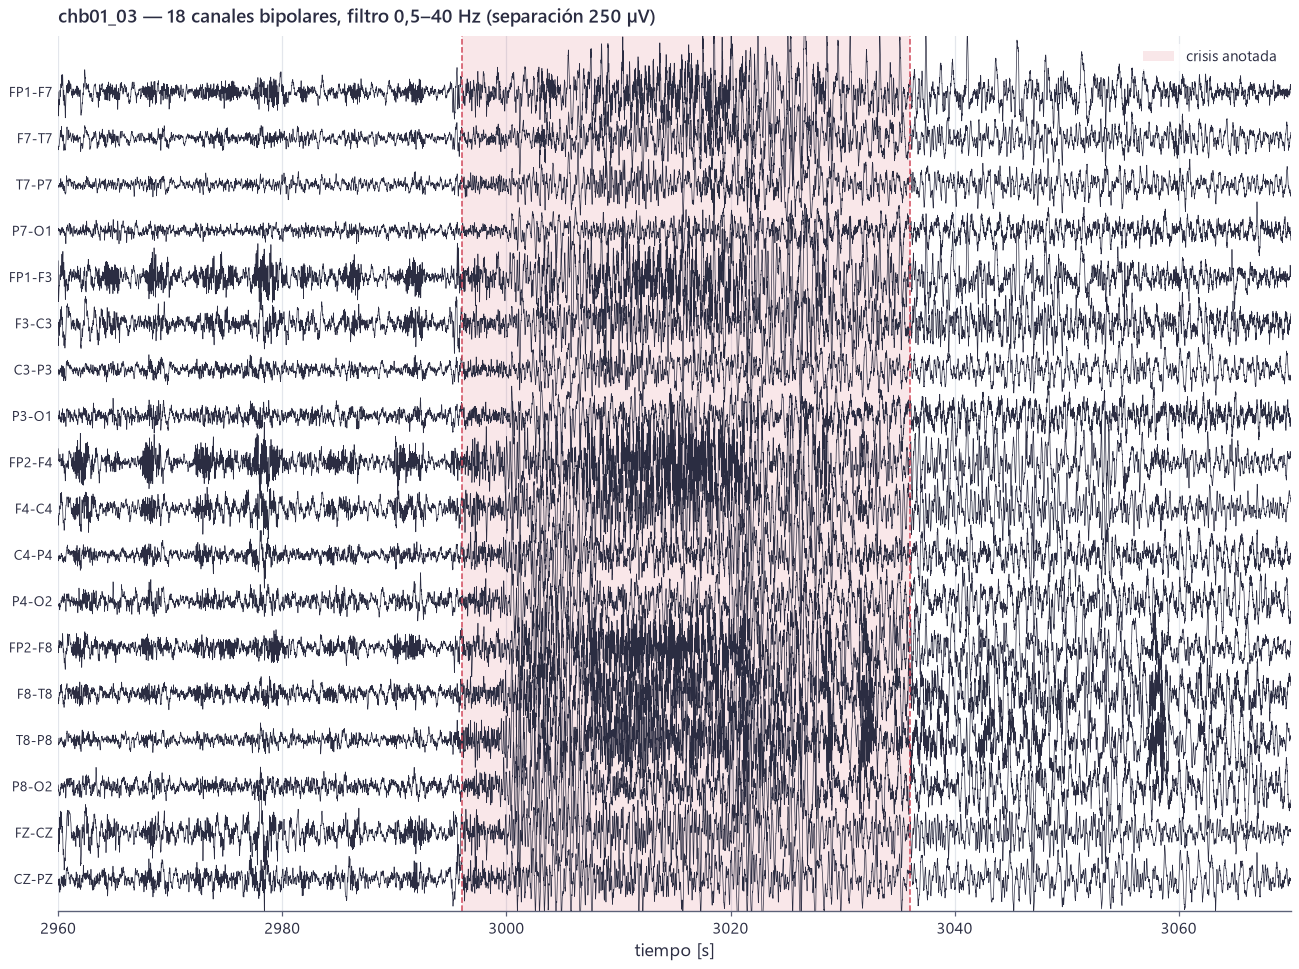

In [3]:
raw = mne.io.read_raw_edf(DATOS / "chb01" / "chb01_03.edf", preload=True).pick(P.CANALES)
x = signal.sosfiltfilt(P.SOS, raw.get_data() * 1e6, axis=-1)
a, b = 2960, 3070
seg = x[:, a * P.FS: b * P.FS]
t = np.arange(seg.shape[1]) / P.FS + a
fig, ax = plt.subplots(figsize=(12, 9))
sep = 250
for k, nombre in enumerate(P.CANALES):
    ax.plot(t, seg[k] - k * sep, lw=0.45, color=EG.TINTA)
ax.set_yticks(-np.arange(len(P.CANALES)) * sep, [c.replace("-0", "") for c in P.CANALES], fontsize=9)
ax.axvspan(2996, 3036, color=EG.ROJO, alpha=0.13, lw=0, label="crisis anotada")
for lim in (2996, 3036):
    ax.axvline(lim, color=EG.ROJO, lw=1, ls="--")
ax.set_xlim(a, b); ax.set_ylim(-(len(P.CANALES) - 0.3) * sep, 1.2 * sep)
ax.set_xlabel("tiempo [s]"); ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")
ax.grid(axis="y", visible=False); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_title(f"chb01_03 — 18 canales bipolares, filtro 0,5–40 Hz (separación {sep} µV)")
fig.tight_layout(); fig.savefig(SALIDA / "chb01_03_crisis_cruda.png")

## 2.3 Espectrograma alrededor de la crisis

Misma STFT que en la Etapa 1 (ventana de Hann), ahora con $f_s = 256$ Hz y ventana de 2 s.
La resolución es $\Delta f = 0{,}5$ Hz y $\Delta t = 1$ s.

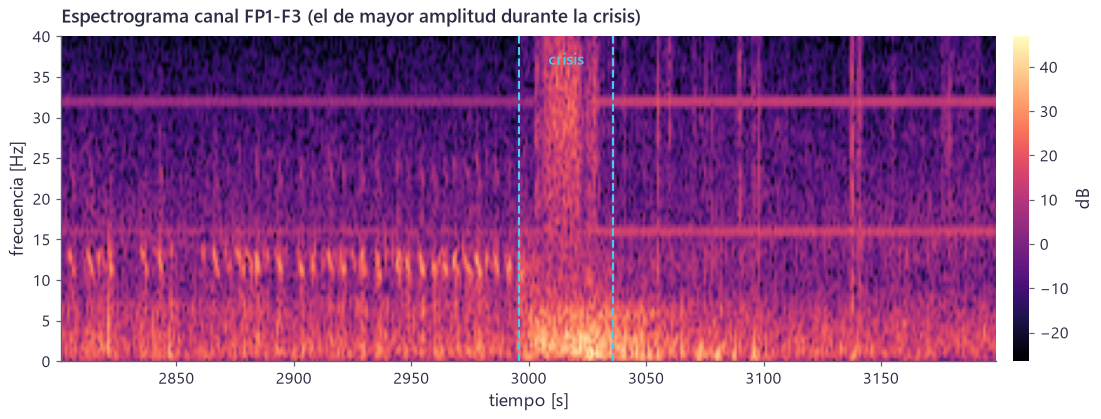

In [4]:
canal = int(np.argmax(seg[:, (2996 - a) * P.FS:(3036 - a) * P.FS].std(axis=1)))
fs_, ts_, Sxx = signal.spectrogram(x[canal, 2800 * P.FS: 3200 * P.FS], fs=P.FS, window="hann",
                                   nperseg=512, noverlap=256)
fig, ax = plt.subplots(figsize=(11, 4))
S_db = 10 * np.log10(Sxx + 1e-6)
vis = S_db[fs_ <= 40]
im = ax.pcolormesh(ts_ + 2800, fs_, S_db, shading="gouraud", cmap=EG.CMAP_ESPECTRO, rasterized=True,
                   vmin=np.percentile(vis, 1), vmax=vis.max())
ax.axvline(2996, c=EG.CIAN, ls="--", lw=1.4); ax.axvline(3036, c=EG.CIAN, ls="--", lw=1.4)
ax.text(3016, 38, "crisis", color=EG.CIAN, ha="center", va="top", fontsize=10.5, fontweight="semibold")
ax.set_ylim(0, 40); ax.set_xlabel("tiempo [s]"); ax.set_ylabel("frecuencia [Hz]"); ax.grid(False)
ax.set_title(f"Espectrograma canal {P.CANALES[canal]} (el de mayor amplitud durante la crisis)")
cb = fig.colorbar(im, label="dB", pad=0.015); cb.outline.set_visible(False)
fig.tight_layout(); fig.savefig(SALIDA / "chb01_03_espectrograma.png")

**Observaciones:**
- Antes de la crisis, las ráfagas de 10–14 Hz en los canales frontales (FP1-F3, FP2-F4) son
  actividad normal. Al empezar la crisis aparece una descarga rítmica de gran amplitud en casi
  todos los canales y la potencia sube en todo el rango 1–40 Hz, sobre todo debajo de 8 Hz.
- Después del fin anotado (3036 s) queda actividad lenta de gran amplitud: es el estado
  **post-ictal**. Se etiqueta como "sin crisis", así que es una fuente esperable de falsas alarmas.
- Las líneas horizontales en ~16 y ~32 Hz están presentes durante todo el registro: son
  interferencia de banda angosta del equipo, no actividad cerebral. Durante la crisis no se ven
  porque la potencia de la descarga es mucho mayor.

## 2.4 Ventanas y etiquetas

Cada registro se corta en ventanas consecutivas, sin solapamiento, de $L = 4$ s (1024 muestras).
Para la ventana $w = [t_0, t_0 + L)$ y una crisis anotada $[a, b]$:

$$y(w) = \begin{cases} 1 & \text{si } a \le t_0 \text{ y } t_0 + L \le b \quad \text{(ictal)} \\
\text{borde} & \text{si la ventana toca la crisis solo en parte} \\
0 & \text{en otro caso} \end{cases}$$

Las ventanas de borde mezclan los dos estados y la anotación de inicio y fin tiene unos segundos de
incertidumbre, así que **no se usan para entrenar**. Al evaluar por eventos (crisis detectada o no)
sí cuentan como parte de la crisis.

Por cada ventana se guardan dos representaciones:

1. **Espectrograma** $\log_{10} S(c, f, \tau)$: 18 canales $\times$ 40 frecuencias (1–40 Hz)
   $\times$ 7 cuadros de 0,5 s. Es la entrada de la CNN.
2. **Potencia por bandas** $\log_{10} P_{c,\text{banda}}$: 18 canales $\times$ 5 bandas = 90 atributos.
   Es la entrada de la regresión logística y del SVM.

Se usa el logaritmo porque la potencia del EEG varía en varios órdenes de magnitud entre canales y
pacientes; con el logaritmo la distribución se parece más a una normal y los factores de ganancia
pasan a ser sumas.

In [5]:
BANDAS = list(P.BANDAS)
bloques = []
for _, fila in indice.iterrows():
    z = np.load(PROC / (Path(fila.archivo).stem + ".npz"))
    n = len(z["t0"])
    bloques.append(dict(bp=z["bp"], ictal=z["ictal"], borde=z["borde"], t0=z["t0"], maxabs=z["maxabs"],
                        paciente=np.full(n, fila.paciente), archivo=np.full(n, fila.archivo)))
D = {k: np.concatenate([bl[k] for bl in bloques]) for k in bloques[0]}
print({k: v.shape for k, v in D.items()})
print("ictales:", int(D["ictal"].sum()), "| borde:", int(D["borde"].sum()),
      "| no ictales:", int(((D["ictal"] == 0) & (D["borde"] == 0)).sum()))

{'bp': (200563, 18, 5), 'ictal': (200563,), 'borde': (200563,), 't0': (200563,), 'maxabs': (200563,), 'paciente': (200563,), 'archivo': (200563,)}
ictales: 711 | borde: 49 | no ictales: 199803


## 2.5 ¿Separa la potencia por bandas las ventanas con crisis?

Promedio sobre los 18 canales del $\log_{10}$ de la potencia por banda, por paciente.

Diferencia media de log10(potencia), crisis menos sin crisis (1 = 10 veces más potencia):


banda,delta,theta,alfa,beta,gamma
paciente,,,,,
chb01,1.19,0.98,0.55,0.41,0.43
chb02,0.99,1.19,1.05,1.25,1.24
chb03,1.25,1.33,1.02,1.18,1.63
chb05,0.68,1.20,1.69,1.67,1.47
chb08,0.83,0.62,0.40,0.39,0.47
chb10,0.34,0.91,1.33,1.29,1.07


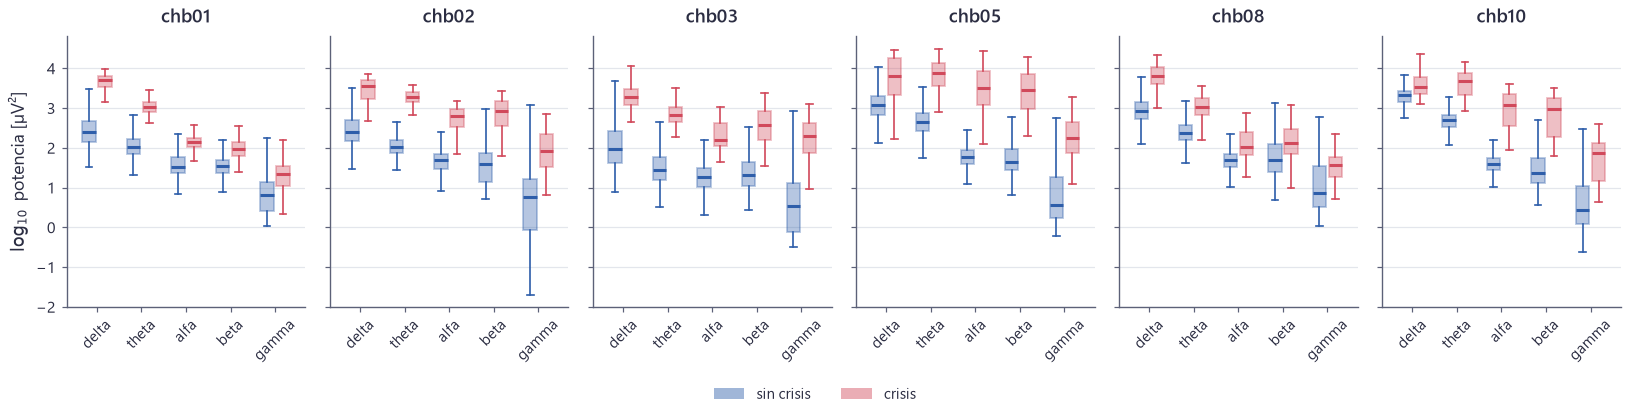

In [6]:
limpio = D["borde"] == 0
bp_media = D["bp"].mean(axis=1)
fig, ejes = plt.subplots(1, len(PACIENTES), figsize=(15, 3.8), sharey=True)
filas = []
for ax, p in zip(ejes, PACIENTES):
    m = (D["paciente"] == p) & limpio
    for etiqueta, color, desp in [(0, EG.AZUL, -0.18), (1, EG.ROJO, 0.18)]:
        v = bp_media[m & (D["ictal"] == etiqueta)]
        ax.boxplot(v, positions=np.arange(5) + desp, widths=0.3, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor=color, alpha=0.35, edgecolor=color, lw=1.2),
                   medianprops=dict(color=color, lw=2), whiskerprops=dict(color=color, lw=1.1),
                   capprops=dict(color=color, lw=1.1))
    for j, banda in enumerate(BANDAS):
        filas.append({"paciente": p, "banda": banda,
                      "dif_log10": bp_media[m & (D["ictal"] == 1), j].mean() - bp_media[m & (D["ictal"] == 0), j].mean()})
    ax.set_xticks(range(5), BANDAS, rotation=45, fontsize=9.5); ax.set_title(p, loc="center")
    ax.grid(axis="x", visible=False)
ejes[0].set_ylabel(r"$\log_{10}$ potencia [µV²]")
fig.legend([plt.Rectangle((0, 0), 1, 1, fc=EG.AZUL, alpha=0.45), plt.Rectangle((0, 0), 1, 1, fc=EG.ROJO, alpha=0.45)],
           ["sin crisis", "crisis"], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.06, 1, 1)); fig.savefig(SALIDA / "potencia_bandas_por_paciente.png")
dif = pd.DataFrame(filas).pivot(index="paciente", columns="banda", values="dif_log10")[BANDAS].round(2)
dif.to_csv(SALIDA / "diferencia_log_potencia_crisis.csv")
print("Diferencia media de log10(potencia), crisis menos sin crisis (1 = 10 veces más potencia):")
dif

**Observaciones:**
- En **todos** los pacientes y en todas las bandas la potencia media sube durante la crisis: entre
  2 y 50 veces ($10^{0{,}3}$ a $10^{1{,}7}$). Esto justifica usar potencia por bandas como atributos.
- Pero **la banda que más cambia depende del paciente**: en chb01 y chb08 es delta, en chb05 y
  chb10 es alfa y beta, y en chb03 sube mucho en todas (sobre todo gamma). Además, el nivel basal es distinto entre pacientes: la potencia delta de
  chb10 **sin** crisis (mediana ≈ 3,3) está cerca de la de chb01 **con** crisis (≈ 3,7), así que un
  umbral fijo sobre una sola banda no sirve para todos. Por eso generalizar a un
  **paciente nuevo** es difícil y la evaluación tiene que hacerse por paciente.

## 2.6 Artefactos de amplitud

El EEG de superficie tiene artefactos (movimiento, electrodos sueltos) que generan amplitudes
muy grandes. Se registra la amplitud máxima de cada ventana; no se descarta nada aquí, porque un
detector real tiene que funcionar con artefactos, pero se usa después para analizar las falsas alarmas.

In [7]:
art = pd.DataFrame({"paciente": D["paciente"], "maxabs": D["maxabs"], "ictal": D["ictal"]})
tabla_art = art.groupby(["paciente", "ictal"]).maxabs.quantile([0.5, 0.99]).unstack().round(0)
tabla_art.columns = ["p50_uV", "p99_uV"]
tabla_art.to_csv(SALIDA / "amplitud_maxima.csv")
tabla_art

p50_uV  p99_uV
paciente ictal                
chb01    0       219.0   963.0
         1       469.0   688.0
chb02    0       197.0  1430.0
         1       700.0  1457.0
chb03    0       178.0  1064.0
         1       739.0  1667.0
chb05    0       330.0  1035.0
         1      1252.0  1728.0
chb08    0       344.0   878.0
         1       618.0  1267.0
chb10    0       339.0  1268.0
         1       927.0  1772.0

## 2.7 Partición de los datos

Las ventanas consecutivas de un mismo registro están muy correlacionadas: si se mezclan al azar
entre entrenamiento y prueba, el modelo "reconoce" el registro y la métrica sale inflada
(*data leakage*). Se usan dos esquemas, ambos sin mezclar ventanas del mismo paciente:

1. **Leave-one-patient-out (LOPO)**: 6 particiones; en cada una se entrena con 5 pacientes y se
   prueba con el que queda afuera. Mide la generalización a un **paciente nuevo**. Se usa para los
   modelos clásicos, que entrenan rápido.
2. **Partición fija** entrenamiento / validación / prueba por paciente, para la CNN y la comparativa de
   optimizadores (correr las 6 particiones con 6 optimizadores y varias semillas sería muy costoso en CPU).
   Se eligió para que cada conjunto tenga una cantidad parecida de segundos de crisis.

In [8]:
PARTICION = {"entrenamiento": ["chb02", "chb05", "chb08"], "validacion": ["chb01"], "prueba": ["chb03", "chb10"]}
part = []
for conjunto, ps in PARTICION.items():
    m = np.isin(D["paciente"], ps)
    part.append({"conjunto": conjunto, "pacientes": ", ".join(ps), "horas": m.sum() * P.VENTANA_S / 3600,
                 "ventanas": int(m.sum()), "ictales": int((m & (D["ictal"] == 1)).sum()),
                 "crisis": int(crisis.paciente.isin(ps).sum())})
part = pd.DataFrame(part).round(1)
part.to_csv(SALIDA / "particion_fija.csv", index=False)
(PROC / "particion.json").write_text(json.dumps({"fija": PARTICION, "lopo": PACIENTES}, indent=2), encoding="utf-8")
part

,conjunto,pacientes,horas,ventanas,ictales,crisis
0,entrenamiento,"chb02, chb05, chb08",94.3,84846,403,13
1,validacion,chb01,40.6,36496,107,7
2,prueba,"chb03, chb10",88.0,79221,201,14


## 2.8 Guardado

Un solo archivo con los atributos de bandas de todas las ventanas (para las etapas de modelos clásicos).
Los espectrogramas quedan en los `.npz` por archivo y se cargan en la etapa de la CNN.

In [9]:
np.savez_compressed(PROC / "chbmit_bandas.npz", bp=D["bp"], ictal=D["ictal"], borde=D["borde"],
                    t0=D["t0"], maxabs=D["maxabs"], paciente=D["paciente"], archivo=D["archivo"],
                    canales=np.array(P.CANALES), bandas=np.array(BANDAS))
meta = {"fs": P.FS, "ventana_s": P.VENTANA_S, "canales": P.CANALES, "bandas_hz": P.BANDAS,
        "filtro": "Butterworth orden 4, pasabanda 0,5-40 Hz, sosfiltfilt",
        "stft": {"ventana": "hann", "nperseg": P.NPERSEG, "noverlap": P.NOVERLAP, "frecuencias": "1-40 Hz"},
        "pacientes": PACIENTES, "particion_fija": PARTICION,
        "fuente": "https://physionet.org/content/chbmit/1.0.0/"}
(SALIDA / "metadatos.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print(sorted(p.name for p in SALIDA.iterdir()))

['amplitud_maxima.csv', 'chb01_03_crisis_cruda.png', 'chb01_03_espectrograma.png', 'diferencia_log_potencia_crisis.csv', 'metadatos.json', 'particion_fija.csv', 'potencia_bandas_por_paciente.png', 'resumen_pacientes.csv']
